# PlasticMuonTiming: variable-SiPM signal + position reconstruction

Target ROOT files:

`/Volumes/ExtremeSSD/Software/PlasticMuonTiming/run/sipm_timing_edge{NEDGE}_*.root`

This notebook supports **nEdgesSiPM = 0, 1, 2, 3**, corresponding to **4, 8, 12, 16 SiPMs** respectively.

The notebook:
- auto-detects all SiPM IDs from the ROOT branches;
- analyzes amplitude and timing of every channel;
- infers each channel's effective spatial response from MC truth, so no SiPM geometry is hard-coded;
- compares amplitude-only, timing-only and amplitude+timing reconstruction;
- evaluates position resolution on an independent test sample.

Main reconstruction methods:
1. effective multi-channel COG;
2. amplitude quadratic regression;
3. timing quadratic regression;
4. amplitude+timing quadratic regression;
5. amplitude template $\chi^2$;
6. timing template $\chi^2$;
7. amplitude+timing template $\chi^2$.

All spatial 2D maps in this version use **regular square bins (25 mm × 25 mm)** rather than hexagonal bins.


In [150]:
# 1. Imports and configuration
from pathlib import Path
import re, numpy as np, pandas as pd, matplotlib.pyplot as plt, uproot
from IPython.display import display

plt.rcParams.update({"figure.dpi":120,"savefig.dpi":180,"font.size":11,
                     "axes.grid":True,"grid.alpha":.25})
pd.set_option("display.max_columns",200)

# NEDGE = 0, 1, 2, 3 -> 4, 8, 12, 16 SiPMs
# NEVENTS = "20k" for 0, "200k" for 2
NEDGE=2
NEVENTS="200k"

RUN=Path("/Volumes/ExtremeSSD/Software/PlasticMuonTiming/run/BatchStudies")
FILES=[
    RUN/f"sipm_timing_edge{NEDGE}_{NEVENTS}.root",
]
FILE=next((p for p in FILES if p.exists()),FILES[0])
OUT=FILE.parent/f"sipm_timing_edge{NEDGE}_analysis"; OUT.mkdir(parents=True,exist_ok=True)

TRAIN_FRAC=.70
SEED=12345
NX=NY=21
MIN_TEMPLATE_EVENTS=5
RIDGE=1e-2

print("Input :",FILE)
print("Output:",OUT)


Input : /Volumes/ExtremeSSD/Software/PlasticMuonTiming/run/BatchStudies/sipm_timing_edge2_200k.root
Output: /Volumes/ExtremeSSD/Software/PlasticMuonTiming/run/BatchStudies/sipm_timing_edge2_analysis


In [151]:
# ============================================================
# 2D plotting helper: regular square spatial bins
# ============================================================
from scipy.stats import binned_statistic_2d

# 25 mm x 25 mm spatial bins for a 1000 x 1000 mm detector
XY_BINS = np.arange(-500, 500 + 25, 25)

def histmap(ax, x, y, z=None, statistic="mean",
            bins=XY_BINS, min_count=3, cbar_label=None,
            vmin=None, vmax=None):
    """
    Regular rectangular 2D spatial map.

    If z is None:
        plot event counts / bin.
    Otherwise:
        plot requested binned statistic of z.

    Bins with fewer than min_count events are masked.
    """
    x=np.asarray(x,float)
    y=np.asarray(y,float)
    good=np.isfinite(x)&np.isfinite(y)

    if z is not None:
        z=np.asarray(z,float)
        good &= np.isfinite(z)
        z=z[good]

    x=x[good]
    y=y[good]

    count,xe,ye,_=binned_statistic_2d(
        x,y,None,statistic="count",bins=[bins,bins]
    )

    if z is None:
        Z=count
    else:
        Z,xe,ye,_=binned_statistic_2d(
            x,y,z,statistic=statistic,bins=[bins,bins]
        )
        Z[count < min_count] = np.nan

    im=ax.pcolormesh(
        xe,ye,Z.T,
        shading="auto",
        vmin=vmin,vmax=vmax
    )

    ax.set_aspect("equal")

    if cbar_label is not None:
        plt.colorbar(im,ax=ax,label=cbar_label)

    return im, count

In [152]:
# 2. Load ROOT + auto-detect all SiPM channels
if not FILE.exists():
    raise FileNotFoundError(f"{FILE}\nChange FILE if needed.")

with uproot.open(FILE) as f:
    print("ROOT objects:",f.classnames())
    events=f["events"].arrays(library="pd").reset_index(drop=True)
    hits=f["hits"].arrays(library="pd").reset_index(drop=True) if "hits" in f else pd.DataFrame()

events=events.replace([np.inf,-np.inf],np.nan)
hits=hits.replace([np.inf,-np.inf],np.nan)

pat=re.compile(r"^n_detected_sipm(\d+)$")
IDS=sorted(int(m.group(1)) for c in events.columns if (m:=pat.match(c)))
if not IDS and "sipm" in hits:
    IDS=sorted(hits.sipm.dropna().astype(int).unique())

NSIPM=len(IDS); EXPECTED=4+4*NEDGE
print("SiPM IDs:",IDS)
print("N SiPMs :",NSIPM)
if NSIPM!=EXPECTED: print(f"WARNING: edge{NEDGE} is expected to contain {EXPECTED} SiPMs.")

print("\nEvent branches:\n",list(events.columns))
print("\nHit branches:\n",list(hits.columns))
display(events.head())


ROOT objects: {'hits;1': 'TTree', 'events;1': 'TTree', 'sipm0_time;1': 'TH1D', 'sipm1_time;1': 'TH1D', 'sipm2_time;1': 'TH1D', 'sipm3_time;1': 'TH1D', 'sipm4_time;1': 'TH1D', 'sipm5_time;1': 'TH1D', 'sipm6_time;1': 'TH1D', 'sipm7_time;1': 'TH1D', 'sipm8_time;1': 'TH1D', 'sipm9_time;1': 'TH1D', 'sipm10_time;1': 'TH1D', 'sipm11_time;1': 'TH1D', 'event_counter;1': 'TH1D', 'sipm0_path;1': 'TH1D', 'sipm1_path;1': 'TH1D', 'sipm2_path;1': 'TH1D', 'sipm3_path;1': 'TH1D', 'sipm4_path;1': 'TH1D', 'sipm5_path;1': 'TH1D', 'sipm6_path;1': 'TH1D', 'sipm7_path;1': 'TH1D', 'sipm8_path;1': 'TH1D', 'sipm9_path;1': 'TH1D', 'sipm10_path;1': 'TH1D', 'sipm11_path;1': 'TH1D', 'source_xy;1': 'TH2D', 'response_sipm0_xy;1': 'TH2D', 'response_sipm1_xy;1': 'TH2D', 'response_sipm2_xy;1': 'TH2D', 'response_sipm3_xy;1': 'TH2D', 'response_sipm4_xy;1': 'TH2D', 'response_sipm5_xy;1': 'TH2D', 'response_sipm6_xy;1': 'TH2D', 'response_sipm7_xy;1': 'TH2D', 'response_sipm8_xy;1': 'TH2D', 'response_sipm9_xy;1': 'TH2D', 'resp

,event,source_x_mm,source_y_mm,n_produced,n_scint_produced,n_cherenkov_produced,n_reach_sipm0,n_reach_sipm1,n_reach_sipm2,n_reach_sipm3,n_reach_sipm4,n_reach_sipm5,n_reach_sipm6,n_reach_sipm7,n_reach_sipm8,n_reach_sipm9,n_reach_sipm10,n_reach_sipm11,n_detected_sipm0,n_detected_sipm1,n_detected_sipm2,n_detected_sipm3,n_detected_sipm4,n_detected_sipm5,n_detected_sipm6,n_detected_sipm7,n_detected_sipm8,n_detected_sipm9,n_detected_sipm10,n_detected_sipm11,n_scint_detected_sipm0,n_scint_detected_sipm1,n_scint_detected_sipm2,n_scint_detected_sipm3,n_scint_detected_sipm4,n_scint_detected_sipm5,n_scint_detected_sipm6,n_scint_detected_sipm7,n_scint_detected_sipm8,n_scint_detected_sipm9,n_scint_detected_sipm10,n_scint_detected_sipm11,n_cherenkov_detected_sipm0,n_cherenkov_detected_sipm1,n_cherenkov_detected_sipm2,n_cherenkov_detected_sipm3,n_cherenkov_detected_sipm4,n_cherenkov_detected_sipm5,n_cherenkov_detected_sipm6,n_cherenkov_detected_sipm7,n_cherenkov_detected_sipm8,n_cherenkov_detected_sipm9,n_cherenkov_detected_sipm10,n_cherenkov_detected_sipm11,first_time_sipm0_ns,first_time_sipm1_ns,first_time_sipm2_ns,first_time_sipm3_ns,first_time_sipm4_ns,first_time_sipm5_ns,first_time_sipm6_ns,first_time_sipm7_ns,first_time_sipm8_ns,first_time_sipm9_ns,first_time_sipm10_ns,first_time_sipm11_ns,mean_time_sipm0_ns,mean_time_sipm1_ns,mean_time_sipm2_ns,mean_time_sipm3_ns,mean_time_sipm4_ns,mean_time_sipm5_ns,mean_time_sipm6_ns,mean_time_sipm7_ns,mean_time_sipm8_ns,mean_time_sipm9_ns,mean_time_sipm10_ns,mean_time_sipm11_ns,mean_path_sipm0_mm,mean_path_sipm1_mm,mean_path_sipm2_mm,mean_path_sipm3_mm,mean_path_sipm4_mm,mean_path_sipm5_mm,mean_path_sipm6_mm,mean_path_sipm7_mm,mean_path_sipm8_mm,mean_path_sipm9_mm,mean_path_sipm10_mm,mean_path_sipm11_mm,charge_sipm0_pc,charge_sipm1_pc,charge_sipm2_pc,charge_sipm3_pc,charge_sipm4_pc,charge_sipm5_pc,charge_sipm6_pc,charge_sipm7_pc,charge_sipm8_pc,charge_sipm9_pc,charge_sipm10_pc,charge_sipm11_pc
0,0,-238.851319,-180.251252,24566,23498,1068,18,23,35,13,23,24,22,21,23,45,45,18,7,10,16,4,9,11,11,13,9,22,25,11,7,10,15,4,9,11,11,13,9,21,23,11,0,0,1,0,0,0,0,0,0,1,2,0,5.980308,3.115591,1.798868,3.742184,4.670697,5.489441,4.839085,3.853404,2.565216,1.446177,1.157351,2.774748,11.521189,10.911233,9.150290,8.565490,8.649020,9.161663,11.548558,13.327951,7.847830,4.619041,5.931867,9.754400,2493.094487,2176.183006,1918.688804,2198.444020,1901.781916,1775.559462,2325.856410,2936.200751,1783.132091,740.787047,1035.627092,2018.727711,7.065599,10.093713,16.149940,4.037485,9.084342,11.103084,11.103084,13.121827,9.084342,22.206168,25.234282,11.103084
1,1,-471.670063,396.047653,24015,22853,1162,20,123,14,16,18,8,15,11,13,24,7,12,10,54,7,11,10,5,7,7,8,8,3,9,10,54,7,11,10,5,7,7,8,8,3,9,0,0,0,0,0,0,0,0,0,0,0,0,3.756749,0.920495,3.839620,6.170615,1.827153,3.194496,4.096610,4.425812,4.593041,5.261202,8.091105,1.689961,10.829940,4.113735,10.007318,14.331741,9.506621,6.729326,13.302457,10.411814,11.531429,7.457392,10.100601,7.920613,2462.114550,352.563796,2413.810120,3232.716041,2271.426525,1377.448965,3129.998294,2126.820938,2668.501955,1554.678254,2203.094710,1819.162836,10.093713,54.506049,7.065599,11.103084,10.093713,5.046856,7.065599,7.065599,8.074970,8.074970,3.028114,9.084342
2,2,250.574551,495.074838,16945,15868,1077,47,16,13,15,5,7,23,4,11,16,12,12,21,6,7,10,4,4,13,2,7,6,5,5,20,6,7,10,4,4,13,2,7,6,5,5,1,0,0,0,0,0,0,0,0,0,0,0,1.100589,4.112341,6.073769,4.271258,9.008886,0.829886,1.786446,6.771199,4.405256,5.174966,4.223136,3.086733,3.710635,15.383367,12.702484,10.903667,10.162338,9.181873,5.259436,9.378714,11.328025,8.203886,11.102968,10.404068,328.052554,795.994972,2794.132531,2295.810249,2482.313610,1759.948328,721.930357,1683.866327,2381.276338,1607.000339,2326.759602,2409.589548,21.196797,6.056228,7.065599,10.093713,4.037485,4.037485,13.121827,2.018743,7.065599,6.056228,5.046856,5.046856
3,3,-2.943667,-497.853974,20308,19191,1117,7,9,14,27,10,12,13,24,4,10,21,10,3,6,4,13,3,6,8,13,3,3,9,3,3,6,4,13,3,6,8,13,3,3,8,3,0,

In [153]:
# 3. Standardize truth, amplitude and timing variables
if "event" not in events: events["event"]=np.arange(len(events))
events["event"]=events.event.astype(int)
if len(hits):
    hits["event"]=hits.event.astype(int)
    hits["sipm"]=hits.sipm.astype(int)

def first(df,names): return next((x for x in names if x in df),None)

X=first(events,["source_x_mm","x_source_mm","source_x","x_true_mm"])
Y=first(events,["source_y_mm","y_source_mm","source_y","y_true_mm"])
if X is None or Y is None: raise KeyError("Truth X/Y branches not found.")
events["source_x_mm"]=events[X]; events["source_y_mm"]=events[Y]

# detected counts, reconstructed from hits if event branches are absent
for i in IDS:
    c=f"n_detected_sipm{i}"
    if c not in events and len(hits):
        s=hits[hits.sipm==i].groupby("event").size()
        events[c]=events.event.map(s).fillna(0)

Ncols=[f"n_detected_sipm{i}" for i in IDS]
events["Ntot"]=events[Ncols].sum(axis=1)
for i in IDS: events[f"f{i}"]=events[f"n_detected_sipm{i}"]/events.Ntot.replace(0,np.nan)

# photon timing
THIT=first(hits,["t_ns","t_plot_ns","time_ns","arrival_time_ns","global_time_ns"]) if len(hits) else None
if THIT:
    hs=hits.dropna(subset=[THIT]).sort_values(["event","sipm",THIT])
    timing={
        "t_first":hs.groupby(["event","sipm"])[THIT].first(),
        "t_first3":hs.groupby(["event","sipm"]).head(3).groupby(["event","sipm"])[THIT].mean(),
        "t_first5":hs.groupby(["event","sipm"]).head(5).groupby(["event","sipm"])[THIT].mean(),
    }
    for name,s in timing.items():
        w=s.unstack(); w.columns=[f"{name}{int(i)}" for i in w.columns]
        events=events.merge(w.reset_index(),on="event",how="left")
else:
    for i in IDS:
        c=first(events,[f"first_time_sipm{i}_ns",f"first_time_sipm{i}",f"t_first_sipm{i}_ns"])
        if c: events[f"t_first3{i}"]=events[c]

T=[f"t_first3{i}" for i in IDS if f"t_first3{i}" in events]
if not T: raise KeyError("No SiPM timing information found.")
events["t_ref"]=events[T].median(axis=1,skipna=True)
for i in IDS:
    events[f"dt{i}"]=events.get(f"t_first3{i}",np.nan)-events.t_ref
events["logN"]=np.log1p(events.Ntot)

print("Photon time branch:",THIT)
print("Mean total detected photons/event:",events.Ntot.mean())
print("Zero signal fraction:",f"{(events.Ntot==0).mean():.3%}")

Photon time branch: t_ns
Mean total detected photons/event: 121.55868
Zero signal fraction: 0.000%


In [154]:
# 4. Per-SiPM signal summary
rows=[]
for i in IDS:
    n=events[f"n_detected_sipm{i}"].to_numpy(float)
    t=events[f"t_first3{i}"].to_numpy(float) if f"t_first3{i}" in events else np.full(len(events),np.nan)
    r={"SiPM":i,"mean_N":np.nanmean(n),"std_N":np.nanstd(n),
       "P(N>=1)":np.mean(n>=1),"mean_fraction":np.nanmean(events[f"f{i}"]),
       "mean_first3_ns":np.nanmean(t),"std_first3_ns":np.nanstd(t)}
    for c,k in [(f"n_reach_sipm{i}","mean_reached"),
                (f"n_scint_detected_sipm{i}","mean_scint"),
                (f"n_cherenkov_detected_sipm{i}","mean_cherenkov")]:
        if c in events:r[k]=events[c].mean()
    if f"n_reach_sipm{i}" in events:
        den=events[f"n_reach_sipm{i}"].sum()
        r["det/reach"]=events[f"n_detected_sipm{i}"].sum()/den if den else np.nan
    rows.append(r)

sipm_summary=pd.DataFrame(rows).set_index("SiPM")
display(sipm_summary.round(4))
sipm_summary.to_csv(OUT/"sipm_signal_summary.csv")

,mean_N,std_N,P(N>=1),mean_fraction,mean_first3_ns,std_first3_ns,mean_reached,mean_scint,mean_cherenkov,det/reach
SiPM,,,,,,,,,,
0,10.1134,20.3040,0.9979,0.0820,1.2385,0.6092,21.4794,9.9709,0.1425,0.4708
1,10.0314,17.5479,0.9977,0.0819,1.2453,0.6055,21.3175,9.8916,0.1398,0.4706
2,10.1047,17.8864,0.9980,0.0823,1.2331,0.6061,21.4590,9.9642,0.1405,0.4709
3,10.0519,17.0767,0.9979,0.0820,1.2392,0.6112,21.3610,9.9098,0.1422,0.4706
4,10.1462,17.0134,0.9978,0.0838,1.0714,0.5057,21.5481,10.0037,0.1425,0.4709
5,10.1567,14.3673,0.9977,0.0841,1.0717,0.5076,21.5482,10.0148,0.1419,0.4713
6,10.0828,15.0512,0.9977,0.0836,1.0806,0.5070,21.4248,9.9420,0.1408,0.4706
7,10.1862,16.9852,0.9975,0.0841,1.0688,0.5061,21.6278,10.0428,0.1434,0.4710
8,10.1591,14.8667,0.9978,0.0841,1.0651,0.5104,21.5837,10.0156,0.1436,0.4707


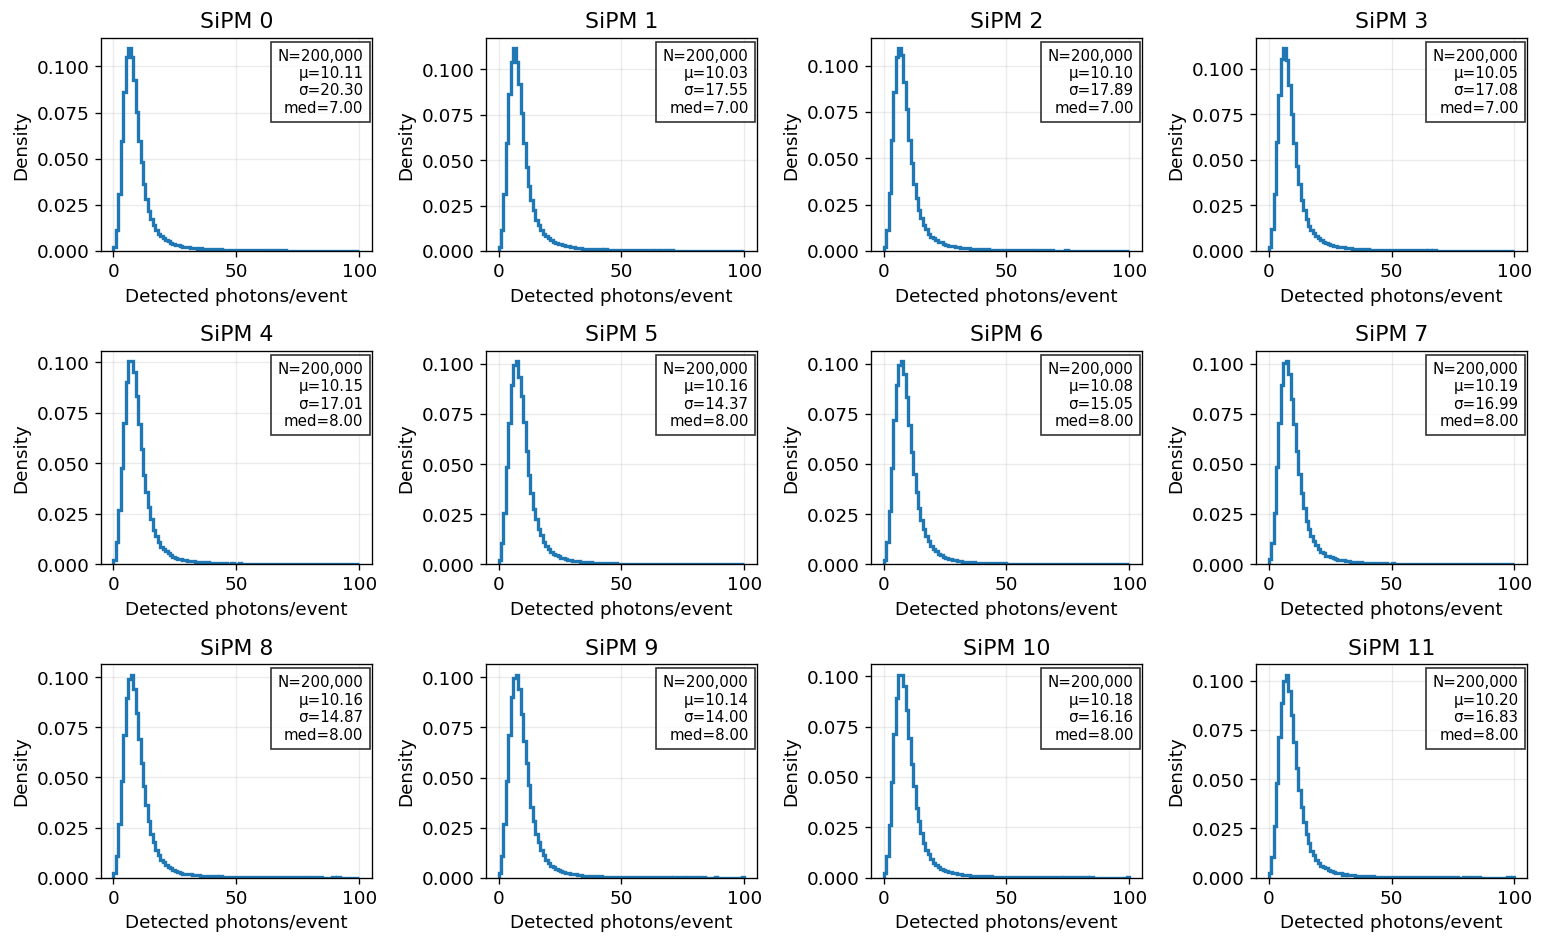

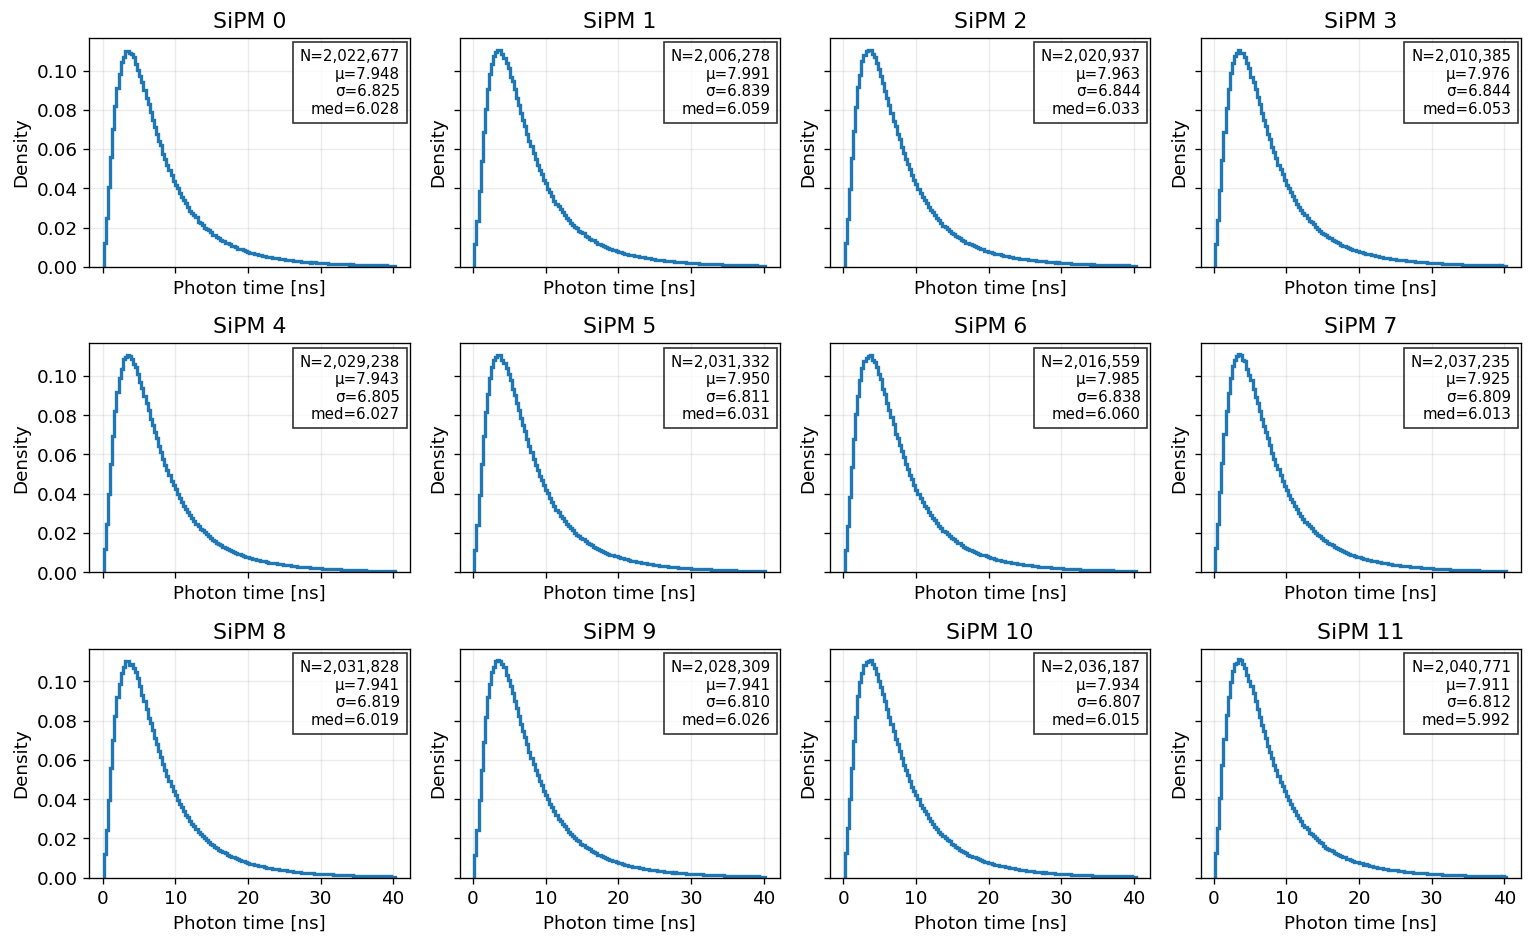

In [155]:
# 5. Detected-signal and dN/dt distributions
NROW=int(np.ceil(NSIPM/4))

# Signal
fig,ax=plt.subplots(NROW,4,figsize=(13,8*NROW/3),squeeze=False)
for a,i in zip(ax.flat,IDS):
    x=events[f"n_detected_sipm{i}"].dropna().to_numpy(float)
    a.hist(x,100,(0,100),histtype="step",density=True,linewidth=2)
    a.text(.97,.95,f"N={len(x):,}\nμ={x.mean():.2f}\nσ={x.std():.2f}\nmed={np.median(x):.2f}",
           transform=a.transAxes,ha="right",va="top",fontsize=9,
           bbox=dict(fc="white",alpha=.8))
    a.set(title=f"SiPM {i}",xlabel="Detected photons/event",ylabel="Density")
for a in ax.flat[NSIPM:]: a.axis("off")
plt.tight_layout(); plt.savefig(OUT/f"01_signal_{NSIPM}sipm.png",bbox_inches="tight"); plt.show()


# dN/dt
if THIT:
    q=hits[THIT].dropna(); lo,hi=np.quantile(q,[.001,.995])
    fig,ax=plt.subplots(NROW,4,figsize=(13,8*NROW/3),squeeze=False,sharex=True,sharey=True)
    for a,i in zip(ax.flat,IDS):
        t=hits.loc[hits.sipm==i,THIT].dropna().to_numpy(float)
        a.hist(t,140,(lo,hi),histtype="step",density=True,linewidth=2)
        a.text(.97,.95,f"N={len(t):,}\nμ={t.mean():.3f}\nσ={t.std():.3f}\nmed={np.median(t):.3f}",
               transform=a.transAxes,ha="right",va="top",fontsize=9,
               bbox=dict(fc="white",alpha=.8))
        a.set(title=f"SiPM {i}",xlabel="Photon time [ns]",ylabel="Density")
    for a in ax.flat[NSIPM:]: a.axis("off")
    plt.tight_layout(); plt.savefig(OUT/f"02_dNdt_{NSIPM}sipm.png",bbox_inches="tight"); plt.show()


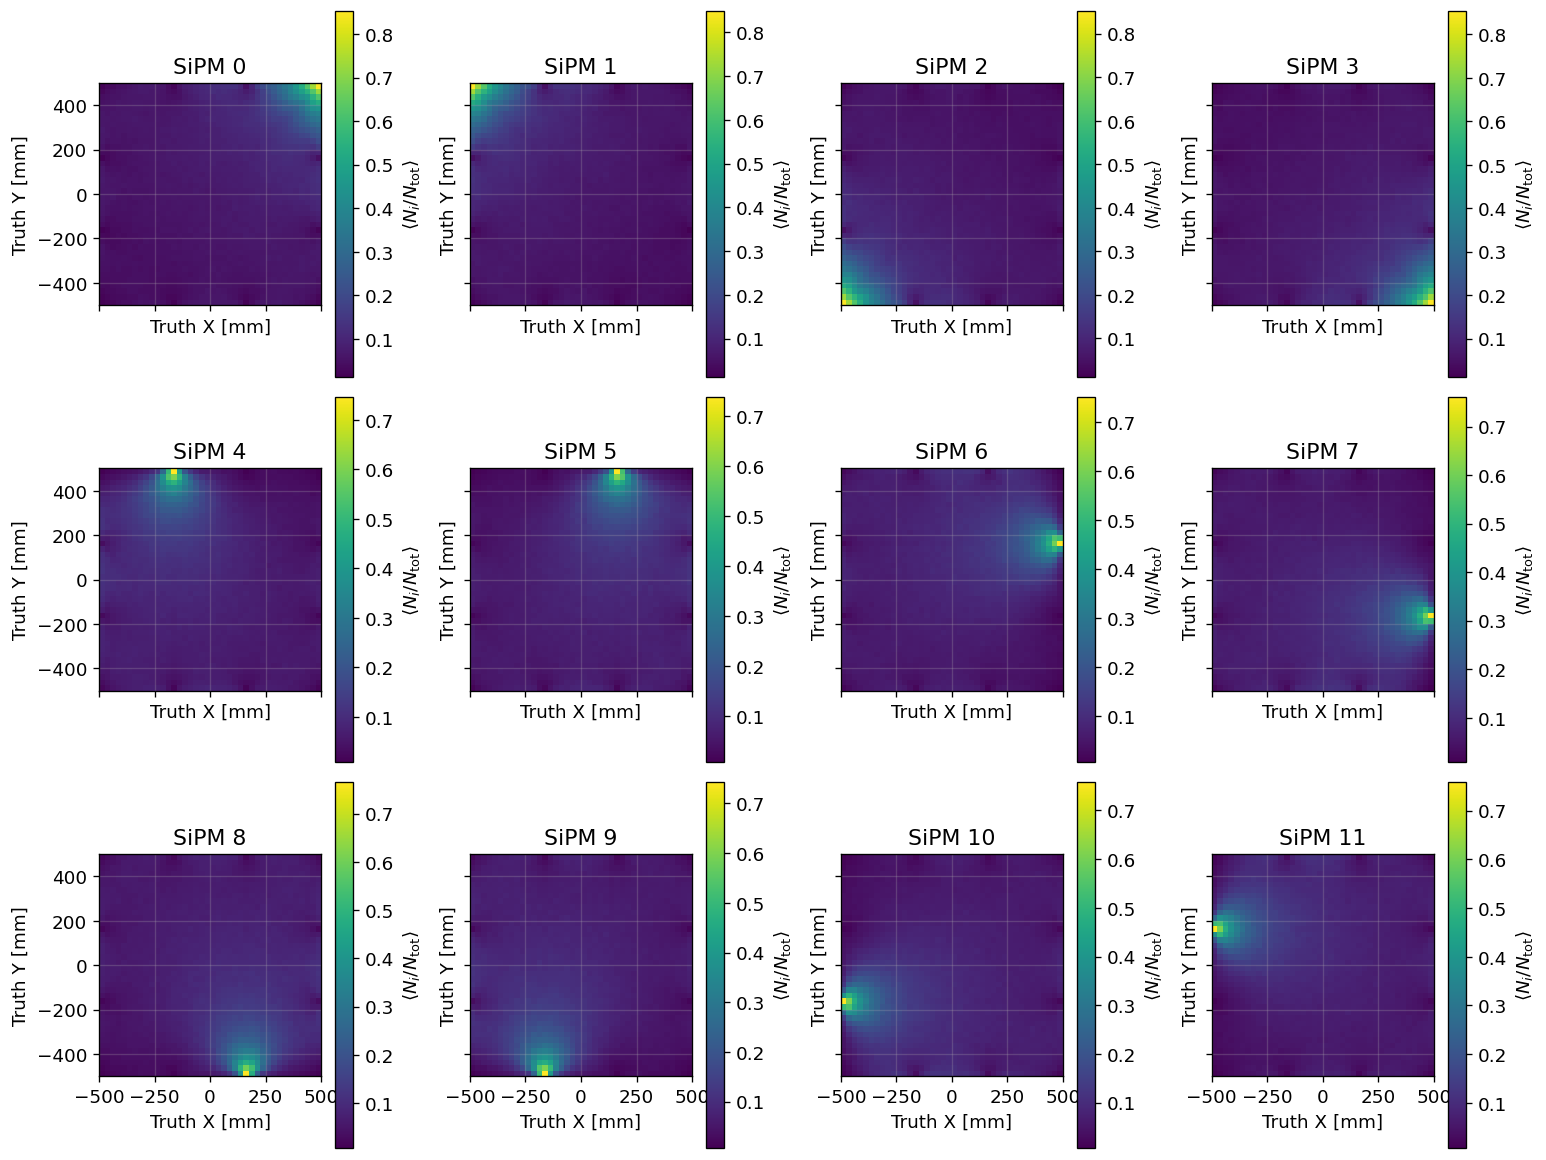

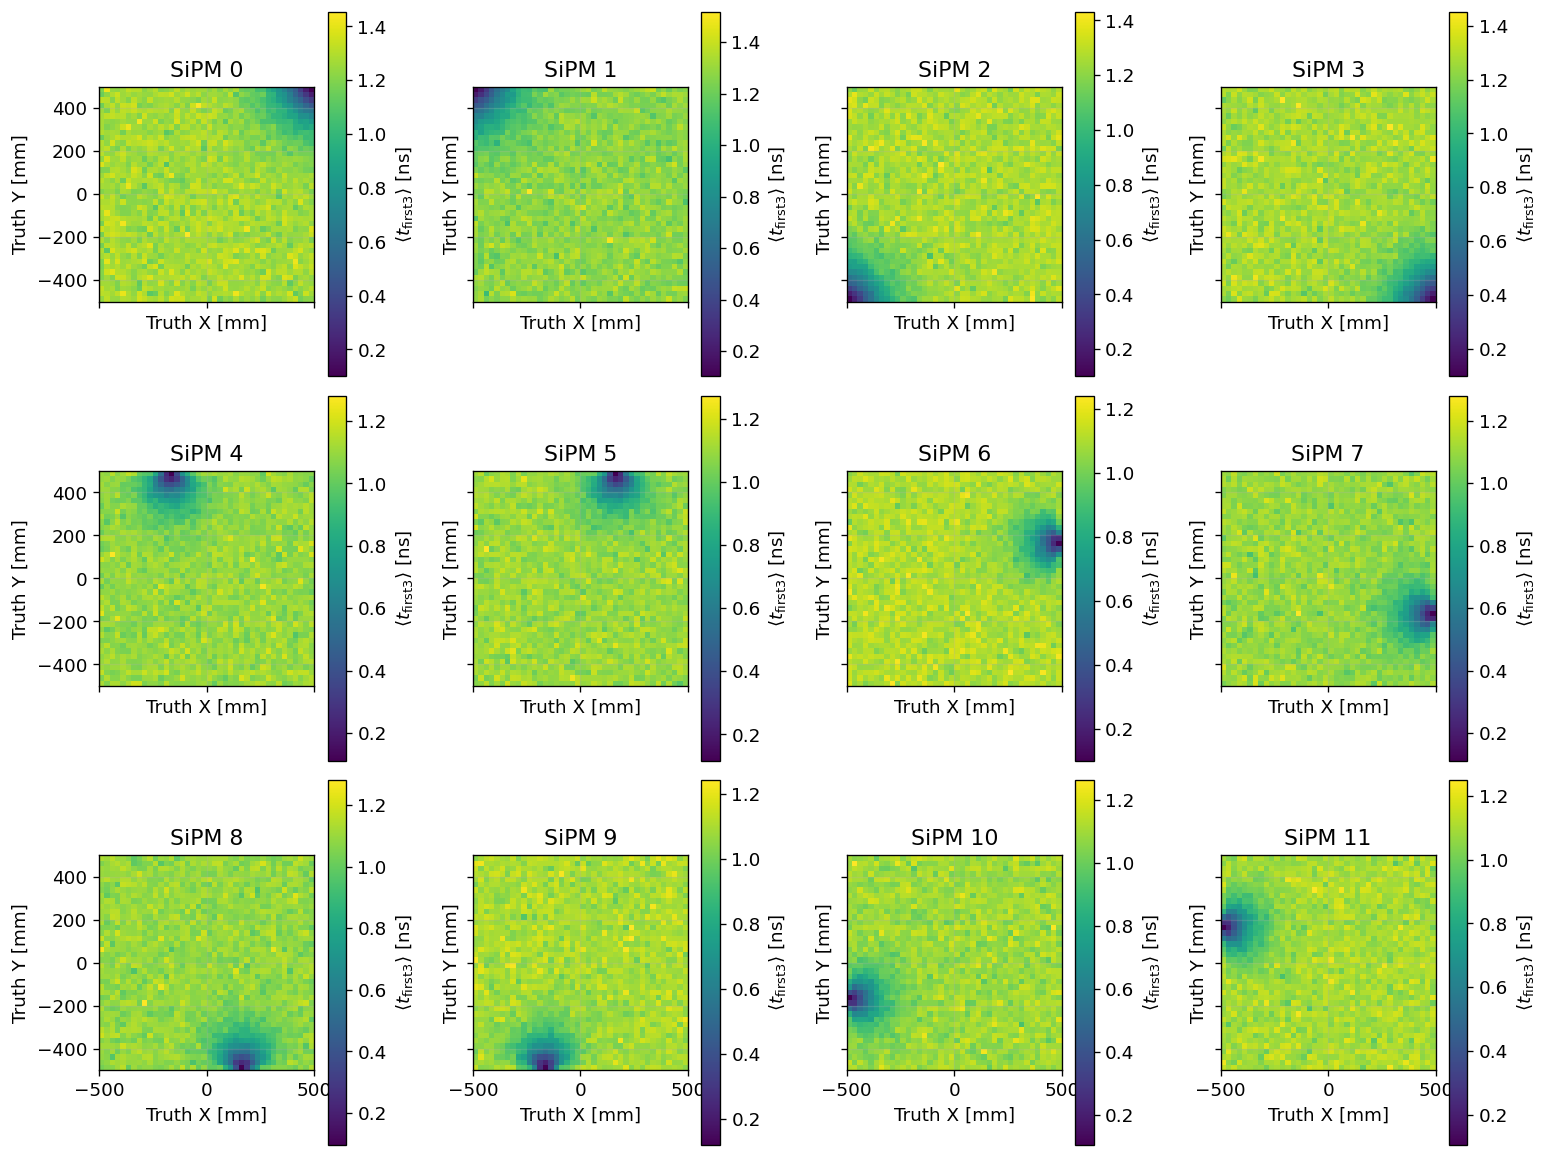

In [156]:
# 6. 2D response maps for all SiPMs
def maps(prefix,label,name):
    NROW=int(np.ceil(NSIPM/4))
    fig,ax=plt.subplots(NROW,4,figsize=(13,10*NROW/3),squeeze=False,sharex=True,sharey=True)
    for a,i in zip(ax.flat,IDS):
        c=f"{prefix}{i}"
        if c not in events:
            a.axis("off")
            continue

        z=events[c].to_numpy(float)

        histmap(a,events["source_x_mm"],events["source_y_mm"],z=z,statistic="mean",bins=XY_BINS,min_count=3,cbar_label=label)
        a.set(title=f"SiPM {i}",xlabel="Truth X [mm]",ylabel="Truth Y [mm]")

    for a in ax.flat[NSIPM:]: a.axis("off")
    plt.tight_layout()
    plt.savefig(OUT/name,bbox_inches="tight")
    plt.show()

maps("f",r"$\langle N_i/N_{\rm tot}\rangle$","03_fraction_maps.png")
maps("t_first3",r"$\langle t_{\rm first3}\rangle$ [ns]","04_timing_maps.png")


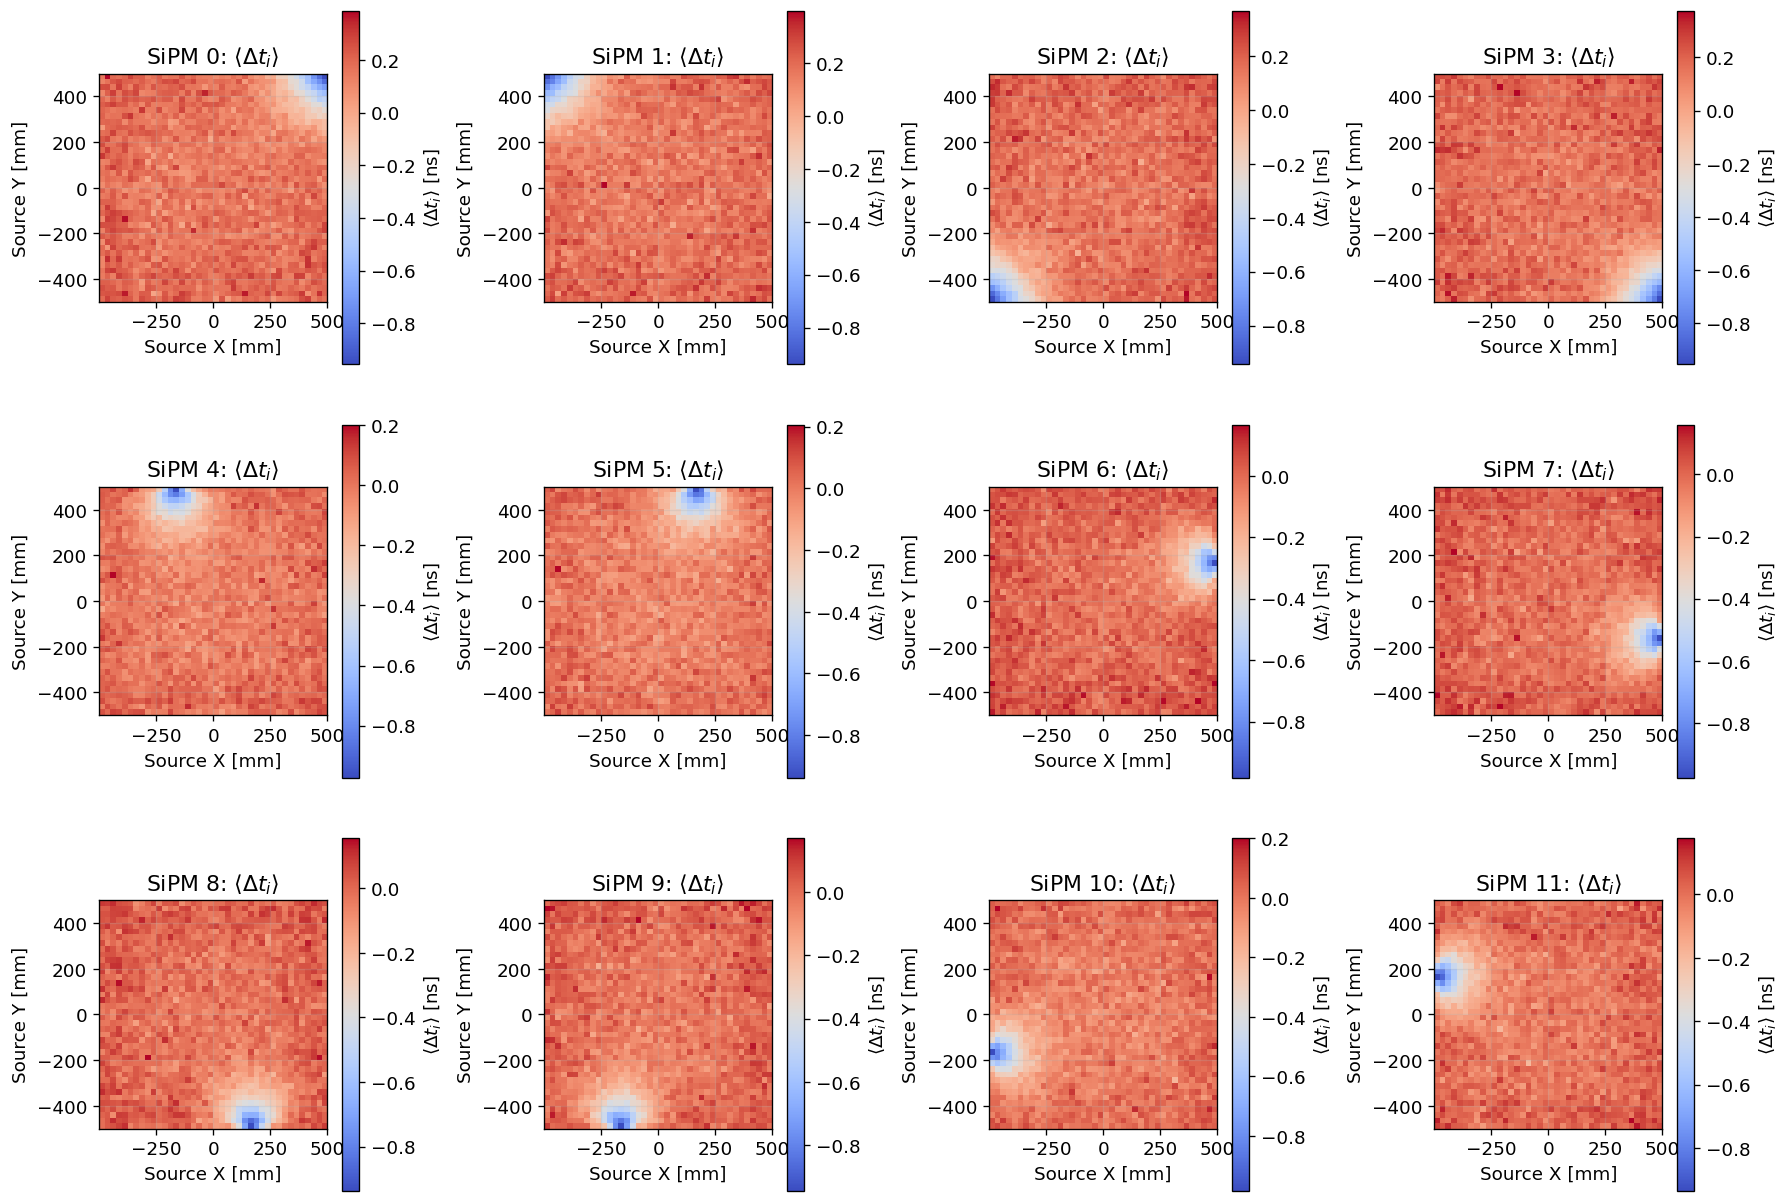

In [157]:
# Figure 4b: <Δt_i>(x,y)
fig,axs=plt.subplots(int(np.ceil(NSIPM/4)),4,figsize=(15,3.5*np.ceil(NSIPM/4)))
axs=np.ravel(axs)

xb=np.arange(events.source_x_mm.min(),events.source_x_mm.max()+25,25)
yb=np.arange(events.source_y_mm.min(),events.source_y_mm.max()+25,25)

for ax,i in zip(axs,IDS):
    x,y,z=events.source_x_mm.values,events.source_y_mm.values,events[f"dt{i}"].values
    ix,iy=np.digitize(x,xb)-1,np.digitize(y,yb)-1
    M=np.array([[np.nanmean(z[(ix==xx)&(iy==yy)]) for xx in range(len(xb)-1)]
                for yy in range(len(yb)-1)])

    im=ax.imshow(M,origin="lower",extent=[*xb[[0,-1]],*yb[[0,-1]]],
                 aspect="equal",cmap="coolwarm")
    ax.set(title=fr"SiPM {i}: $\langle\Delta t_i\rangle$",
           xlabel="Source X [mm]",ylabel="Source Y [mm]")
    plt.colorbar(im,ax=ax,label=r"$\langle\Delta t_i\rangle$ [ns]")

for ax in axs[len(IDS):]: ax.axis("off")

plt.tight_layout()
plt.savefig(OUT/f"04b_dt_maps_{NSIPM}sipm.png",dpi=200,bbox_inches="tight")
plt.show()

## 7. Identify the channel positions from their response

Instead of guessing which channel number is a corner or edge sensor, the notebook calculates an effective response centroid

$$
(x_i^\mathrm{eff},y_i^\mathrm{eff})
=
\frac{\sum_e f_{ie}(x_e,y_e)}{\sum_e f_{ie}}.
$$

The resulting figure should reveal the channel-number topology: four corner-like channels plus the available edge channels.


,x_eff_mm,y_eff_mm
SiPM,,
0,110.90,110.74
1,-110.80,110.88
2,-112.04,-111.48
3,111.13,-110.63
4,-64.03,65.12
5,63.82,65.34
6,63.87,63.75
7,65.88,-63.68
8,64.23,-66.33


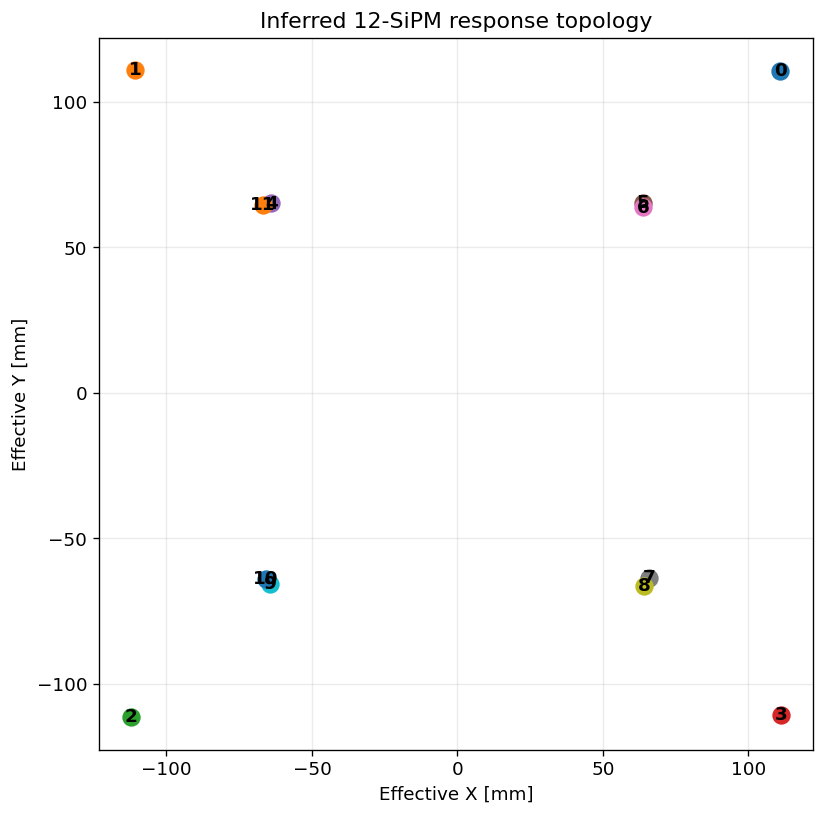

In [158]:
# 7. Inferred response topology
eff={}
for i in IDS:
    w=events[f"f{i}"].fillna(0).to_numpy(float)
    s=w.sum()
    eff[i]=(np.sum(w*events.source_x_mm)/s,np.sum(w*events.source_y_mm)/s) if s else (np.nan,np.nan)

eff_df=pd.DataFrame([{"SiPM":i,"x_eff_mm":eff[i][0],"y_eff_mm":eff[i][1]} for i in IDS]).set_index("SiPM")
display(eff_df.round(2)); eff_df.to_csv(OUT/"sipm_effective_positions.csv")

fig,ax=plt.subplots(figsize=(7,7))
for i,(x,y) in eff.items():
    ax.scatter(x,y,s=100); ax.text(x,y,str(i),ha="center",va="center",fontweight="bold")
ax.set(xlabel="Effective X [mm]",ylabel="Effective Y [mm]",
       title=f"Inferred {NSIPM}-SiPM response topology",aspect="equal")
plt.tight_layout(); plt.savefig(OUT/"05_inferred_topology.png",bbox_inches="tight"); plt.show()

In [159]:
# 8. Train/test split
base=events[np.isfinite(events.source_x_mm)&np.isfinite(events.source_y_mm)&(events.Ntot>0)].copy().reset_index(drop=True)
rng=np.random.default_rng(SEED); idx=rng.permutation(len(base)); n=int(TRAIN_FRAC*len(base))
train=base.iloc[idx[:n]].reset_index(drop=True)
test =base.iloc[idx[n:]].reset_index(drop=True)
print(f"Usable={len(base):,}, train={len(train):,}, test={len(test):,}")

Usable=200,000, train=140,000, test=60,000


In [160]:
# 9. Reconstruction functions
def qexpand(X):
    X=np.asarray(X,float); out=[np.ones((len(X),1)),X,X**2]
    out += [X[:,i:i+1]*X[:,j:j+1] for i in range(X.shape[1]) for j in range(i+1,X.shape[1])]
    return np.hstack(out)

def ridge_xy(tr,te,feat,lam=1e-2):
    med=tr[feat].median()
    A=tr[feat].fillna(med).to_numpy(float); B=te[feat].fillna(med).to_numpy(float)
    mu=A.mean(0); sd=A.std(0); sd[~np.isfinite(sd)|(sd==0)]=1
    A=qexpand((A-mu)/sd); B=qexpand((B-mu)/sd)
    Y=tr[["source_x_mm","source_y_mm"]].to_numpy(float)
    G=A.T@A+lam*np.eye(A.shape[1]); G[0,0]-=lam
    return B@np.linalg.solve(G,A.T@Y)

def template_xy(tr,te,feat,nx=21,ny=21,minn=5,chunk=1500):
    med=tr[feat].median()
    A=tr[feat].fillna(med); Q=te[feat].fillna(med).to_numpy(float)
    scale=A.std().to_numpy(float); scale[~np.isfinite(scale)|(scale<1e-9)]=1
    xe=np.linspace(tr.source_x_mm.min(),tr.source_x_mm.max(),nx+1)
    ye=np.linspace(tr.source_y_mm.min(),tr.source_y_mm.max(),ny+1)
    d=tr[["source_x_mm","source_y_mm"]].copy(); d[feat]=A
    d["ix"]=np.clip(np.digitize(d.source_x_mm,xe)-1,0,nx-1)
    d["iy"]=np.clip(np.digitize(d.source_y_mm,ye)-1,0,ny-1)
    g=d.groupby(["ix","iy"]); good=g.size(); good=good[good>=minn].index
    R=[]
    for k in good:
        z=g.get_group(k)
        R.append([z.source_x_mm.mean(),z.source_y_mm.mean(),*z[feat].mean().to_numpy(float)])
    R=np.asarray(R,float); pos=R[:,:2]; resp=R[:,2:]/scale; Q=Q/scale
    out=np.empty((len(te),2))
    for s in range(0,len(te),chunk):
        q=Q[s:s+chunk]; chi=((q[:,None,:]-resp[None,:,:])**2).sum(2)
        out[s:s+len(q)]=pos[np.argmin(chi,1)]
    return out,len(pos)

def metrics(name,truth,xy):
    xt=truth.source_x_mm.to_numpy(float); yt=truth.source_y_mm.to_numpy(float)
    xr,yr=xy[:,0],xy[:,1]; m=np.isfinite(xr)&np.isfinite(yr)
    dx=xr[m]-xt[m]; dy=yr[m]-yt[m]; r=np.hypot(dx,dy)
    sx,sy=np.std(dx,ddof=1),np.std(dy,ddof=1)
    return {"method":name,"N":m.sum(),"bias_x_mm":dx.mean(),"bias_y_mm":dy.mean(),
            "sigma_x_mm":sx,"sigma_y_mm":sy,"sigma_xy_mm":np.sqrt((sx*sx+sy*sy)/2),
            "FWHM_x_mm":2.355*sx,"FWHM_y_mm":2.355*sy,
            "RMSE_x_mm":np.sqrt(np.mean(dx*dx)),"RMSE_y_mm":np.sqrt(np.mean(dy*dy)),
            "R68_mm":np.quantile(r,.68),"R90_mm":np.quantile(r,.90)}

In [161]:
# 10. Run all reconstruction algorithms
F=[f"f{i}" for i in IDS]
D=[f"dt{i}" for i in IDS]
pred={}

# effective COG baseline
N=test[[f"n_detected_sipm{i}" for i in IDS]].to_numpy(float)
P=np.array([eff[i] for i in IDS])
pred[f"{NSIPM}-SiPM effective COG"]=(N@P)/N.sum(1,keepdims=True)

# regressions
pred["Amplitude regression"]=ridge_xy(train,test,F+["logN"],RIDGE)
pred["Timing regression"]=ridge_xy(train,test,D,RIDGE)
pred["Amplitude + timing regression"]=ridge_xy(train,test,F+D+["logN"],RIDGE)

# response templates
pred["Amplitude template chi2"],na=template_xy(train,test,F,NX,NY,MIN_TEMPLATE_EVENTS)
pred["Timing template chi2"],nt=template_xy(train,test,D,NX,NY,MIN_TEMPLATE_EVENTS)
pred["Amplitude + timing template chi2"],nat=template_xy(train,test,F+D,NX,NY,MIN_TEMPLATE_EVENTS)

print("Templates:",{"A":na,"T":nt,"A+T":nat})

/var/folders/w2/dqj_zlz54yv95s29pvx821600000gn/T/ipykernel_33479/1769165931.py:9: RuntimeWarning: divide by zero encountered in matmul
  pred[f"{NSIPM}-SiPM effective COG"]=(N@P)/N.sum(1,keepdims=True)
/var/folders/w2/dqj_zlz54yv95s29pvx821600000gn/T/ipykernel_33479/1769165931.py:9: RuntimeWarning: overflow encountered in matmul
  pred[f"{NSIPM}-SiPM effective COG"]=(N@P)/N.sum(1,keepdims=True)
/var/folders/w2/dqj_zlz54yv95s29pvx821600000gn/T/ipykernel_33479/1769165931.py:9: RuntimeWarning: invalid value encountered in matmul
  pred[f"{NSIPM}-SiPM effective COG"]=(N@P)/N.sum(1,keepdims=True)
/var/folders/w2/dqj_zlz54yv95s29pvx821600000gn/T/ipykernel_33479/677820924.py:13: RuntimeWarning: divide by zero encountered in matmul
  G=A.T@A+lam*np.eye(A.shape[1]); G[0,0]-=lam
/var/folders/w2/dqj_zlz54yv95s29pvx821600000gn/T/ipykernel_33479/677820924.py:13: RuntimeWarning: overflow encountered in matmul
  G=A.T@A+lam*np.eye(A.shape[1]); G[0,0]-=lam
/var/folders/w2/dqj_zlz54yv95s29pvx821600000g

Templates: {'A': 441, 'T': 441, 'A+T': 441}


In [162]:
# 11. Position-resolution table
summary=pd.DataFrame([metrics(k,test,v) for k,v in pred.items()]).sort_values("R68_mm").reset_index(drop=True)
display(summary.round(3))
summary.to_csv(OUT/"position_resolution_summary.csv",index=False)
best=summary.iloc[0].method
print("Best by R68:",best)

,method,N,bias_x_mm,bias_y_mm,sigma_x_mm,sigma_y_mm,sigma_xy_mm,FWHM_x_mm,FWHM_y_mm,RMSE_x_mm,RMSE_y_mm,R68_mm,R90_mm
0,Amplitude template chi2,60000,-0.495,-0.136,103.118,104.204,103.662,242.844,245.400,103.119,104.203,113.602,226.298
1,Amplitude + timing template chi2,60000,-0.178,-1.281,110.995,111.005,111.000,261.393,261.417,110.994,111.011,126.616,241.990
2,Amplitude + timing regression,60000,0.015,0.587,109.033,108.946,108.989,256.773,256.567,109.032,108.946,152.681,233.996
3,Amplitude regression,60000,-0.051,0.630,109.370,109.404,109.387,257.567,257.645,109.369,109.404,153.385,234.454
4,12-SiPM effective COG,60000,0.003,-0.122,265.391,265.475,265.433,624.996,625.194,265.389,265.473,429.494,515.525
5,Timing regression,60000,-0.161,-0.538,284.450,284.621,284.536,669.880,670.283,284.448,284.619,453.772,553.742
6,Timing template chi2,60000,-8.833,-8.496,459.964,460.457,460.211,1083.215,1084.377,460.045,460.532,751.605,946.974


Best by R68: Amplitude template chi2


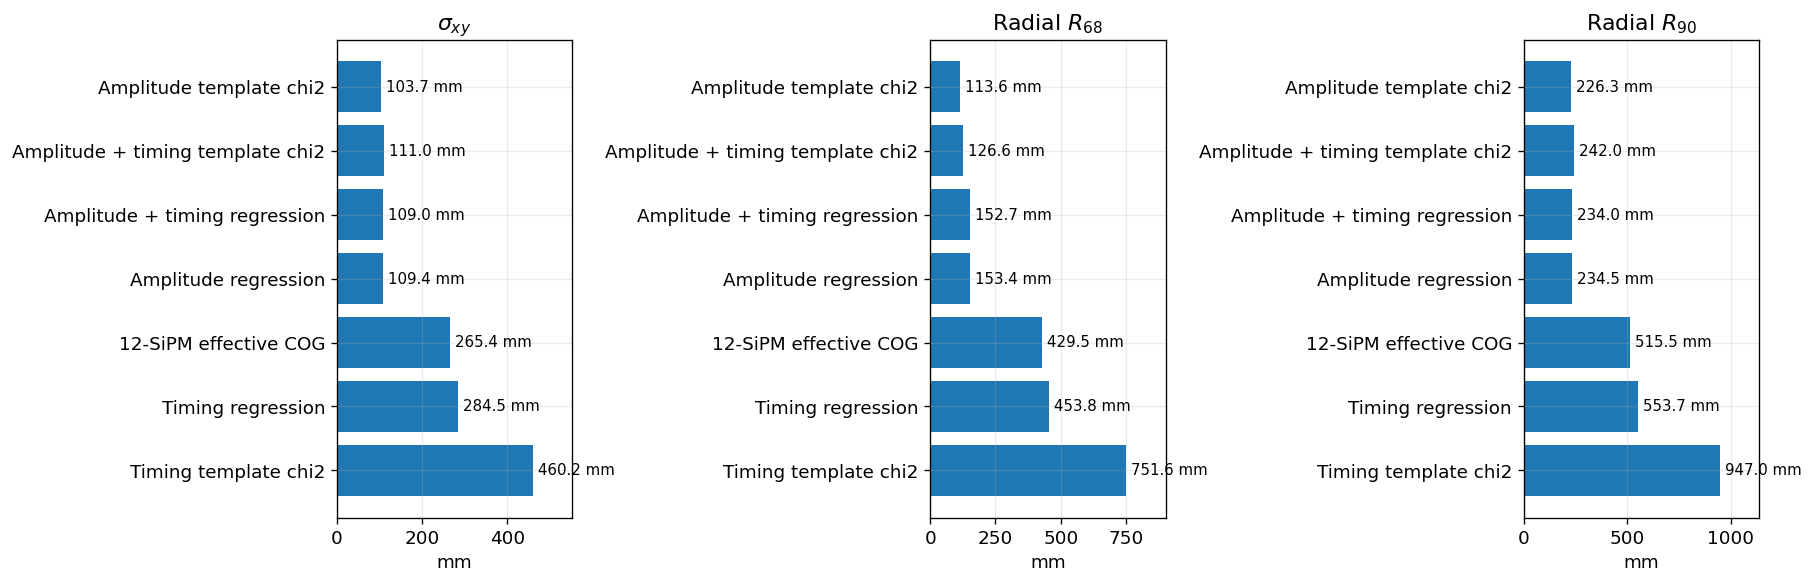

Best σxy : Amplitude template chi2
Best R68 : Amplitude template chi2
Best R90 : Amplitude template chi2


In [163]:
# 12. Compare algorithms
fig,ax=plt.subplots(1,3,figsize=(15,5))
for a,c,title in zip(ax,["sigma_xy_mm","R68_mm","R90_mm"],
                     [r"$\sigma_{xy}$","Radial $R_{68}$","Radial $R_{90}$"]):
    values = summary[c].to_numpy()
    bars = a.barh(summary.method, values)
    a.bar_label(bars, labels=[f"{value:.1f} mm" for value in values],
                padding=3, fontsize=9)
    a.invert_yaxis()
    xmax = np.nanmax(values)
    a.set_xlim(0, 1.20*xmax if xmax > 0 else 1)
    a.set(xlabel="mm", title=title)
plt.tight_layout(); plt.savefig(OUT/"06_algorithm_comparison.png",bbox_inches="tight"); plt.show()
best_sigma = summary.loc[summary["sigma_xy_mm"].idxmin(),"method"]
best_R68   = summary.loc[summary["R68_mm"].idxmin(),"method"]
best_R90   = summary.loc[summary["R90_mm"].idxmin(),"method"]

print("Best σxy :",best_sigma)
print("Best R68 :",best_R68)
print("Best R90 :",best_R90)

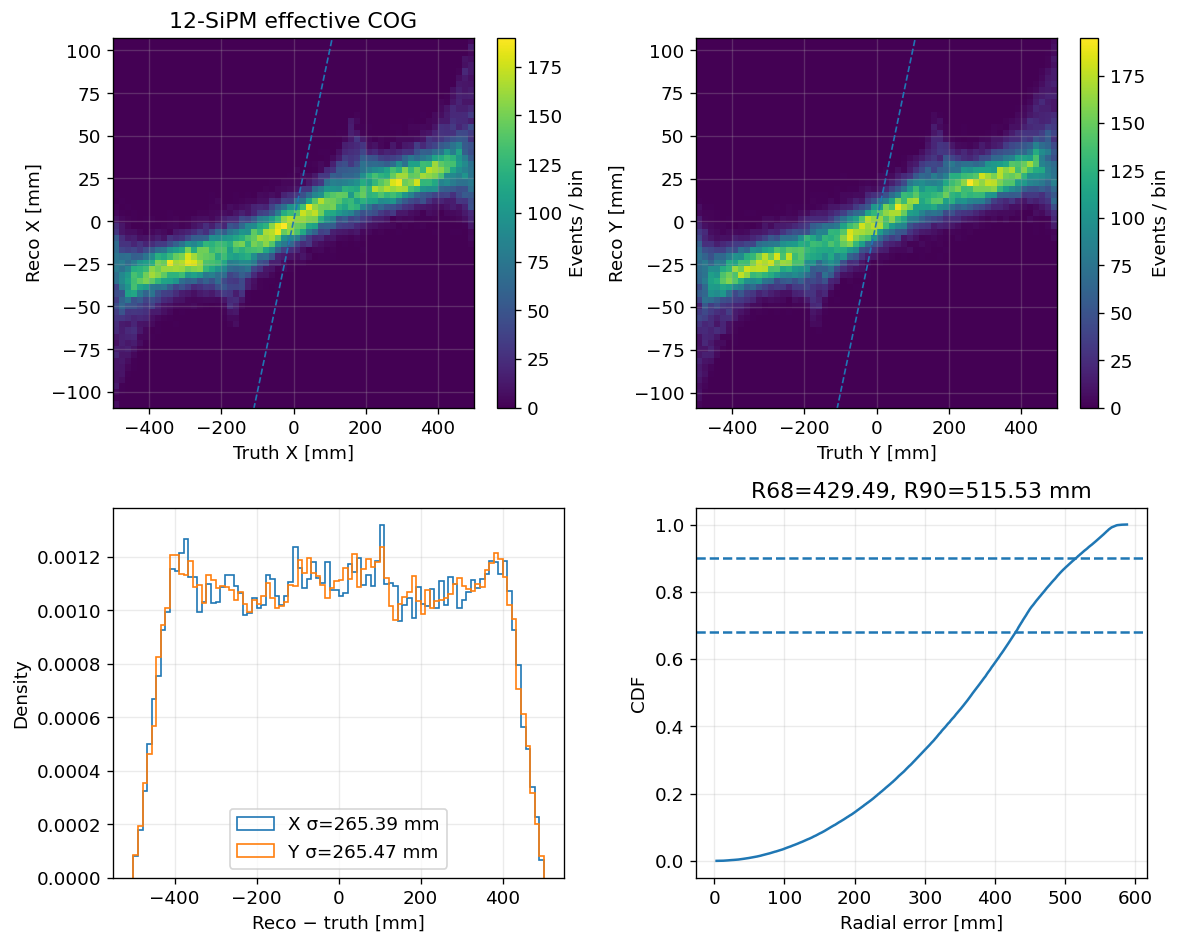

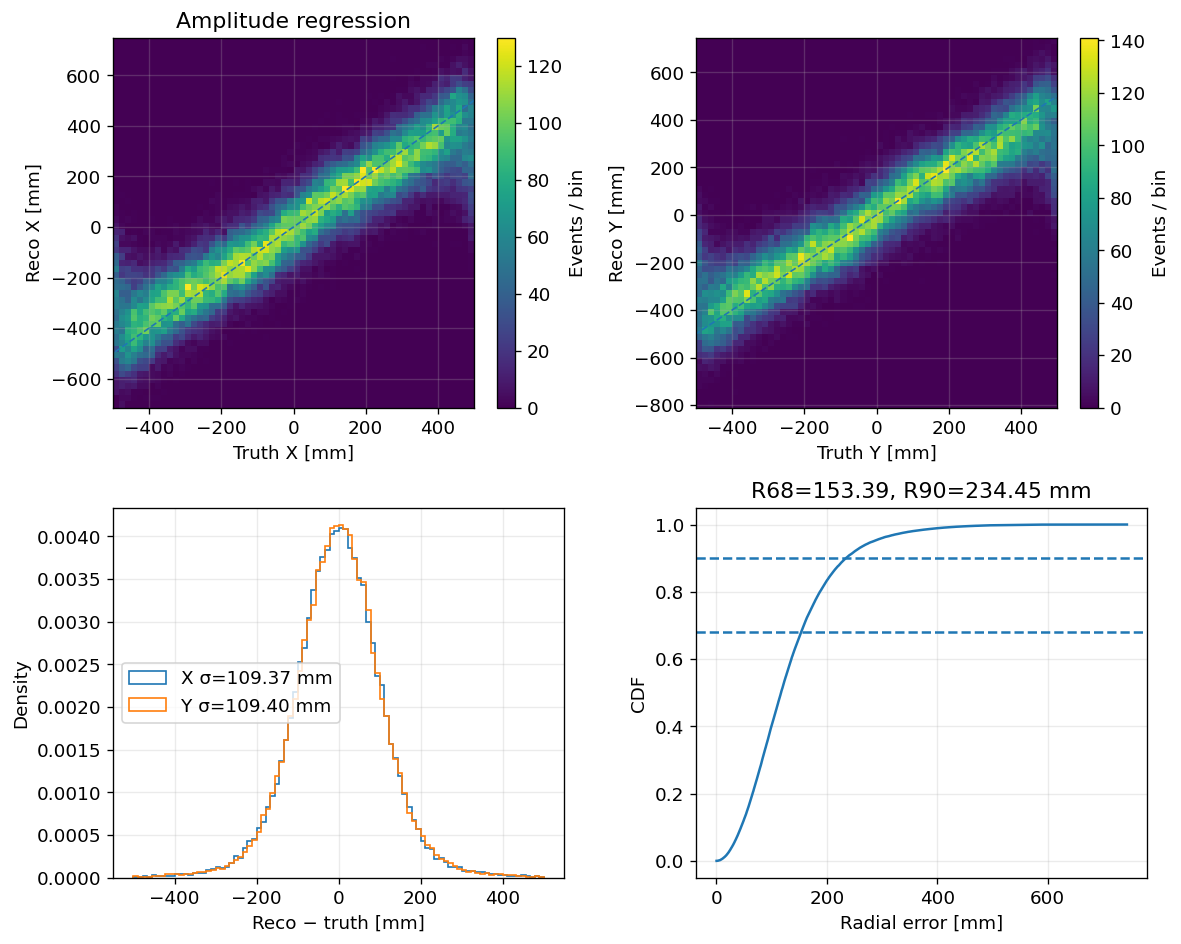

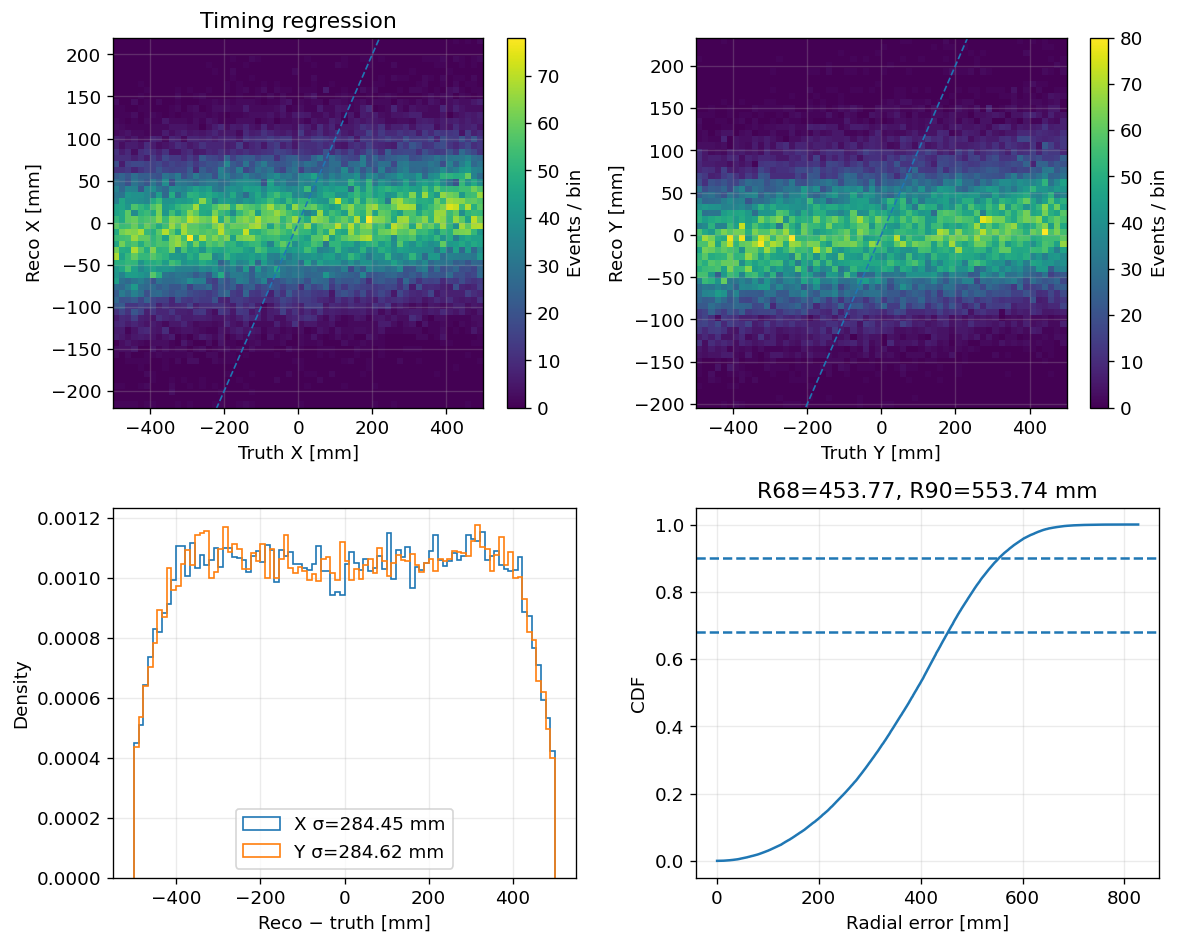

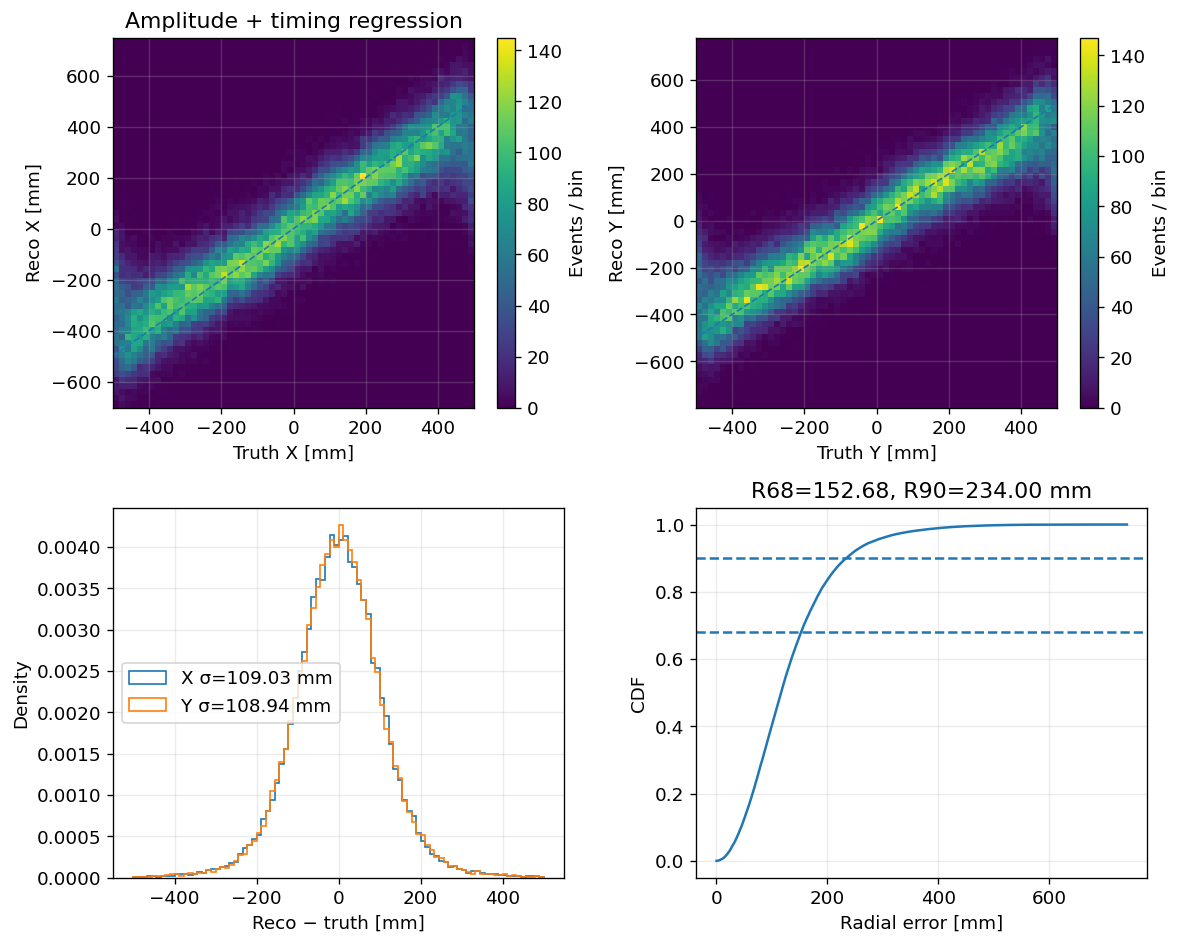

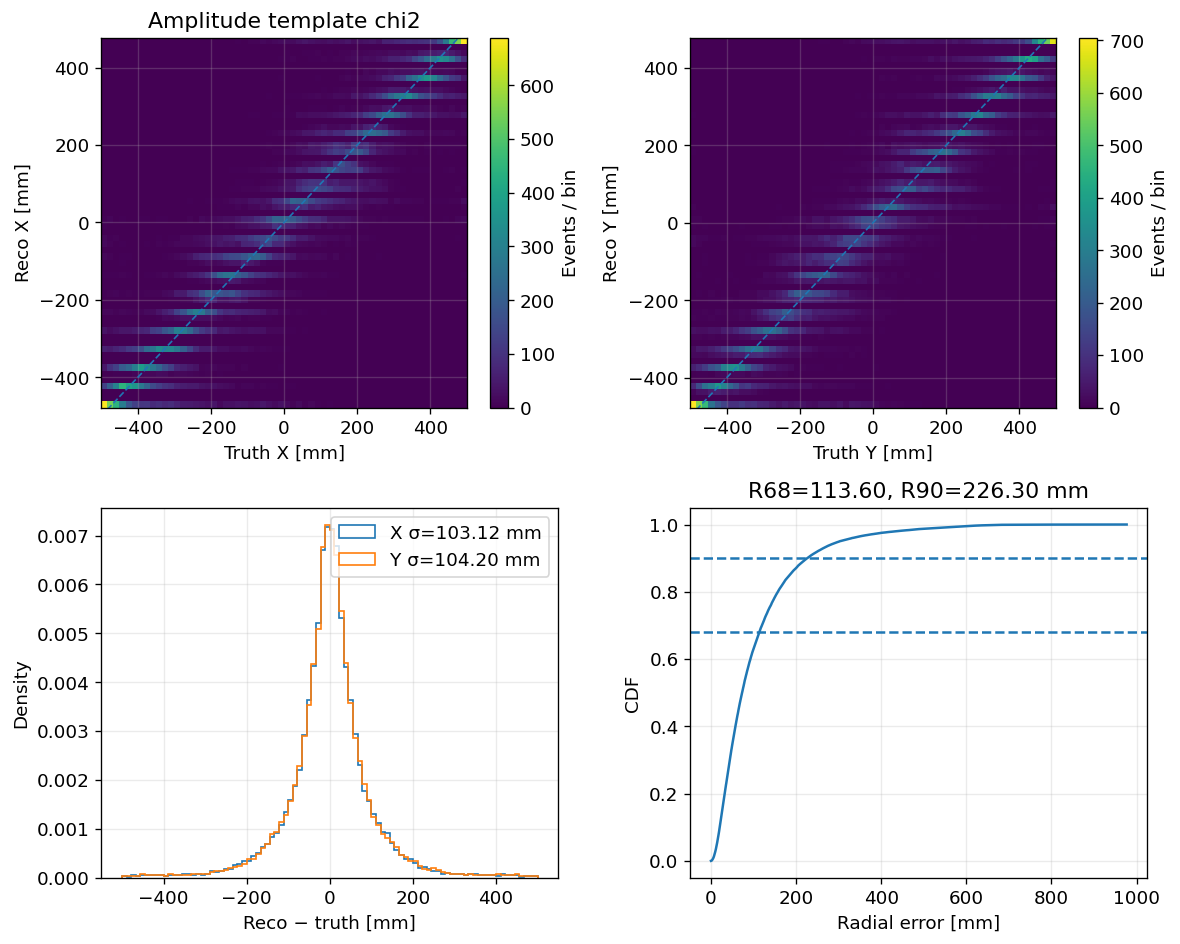

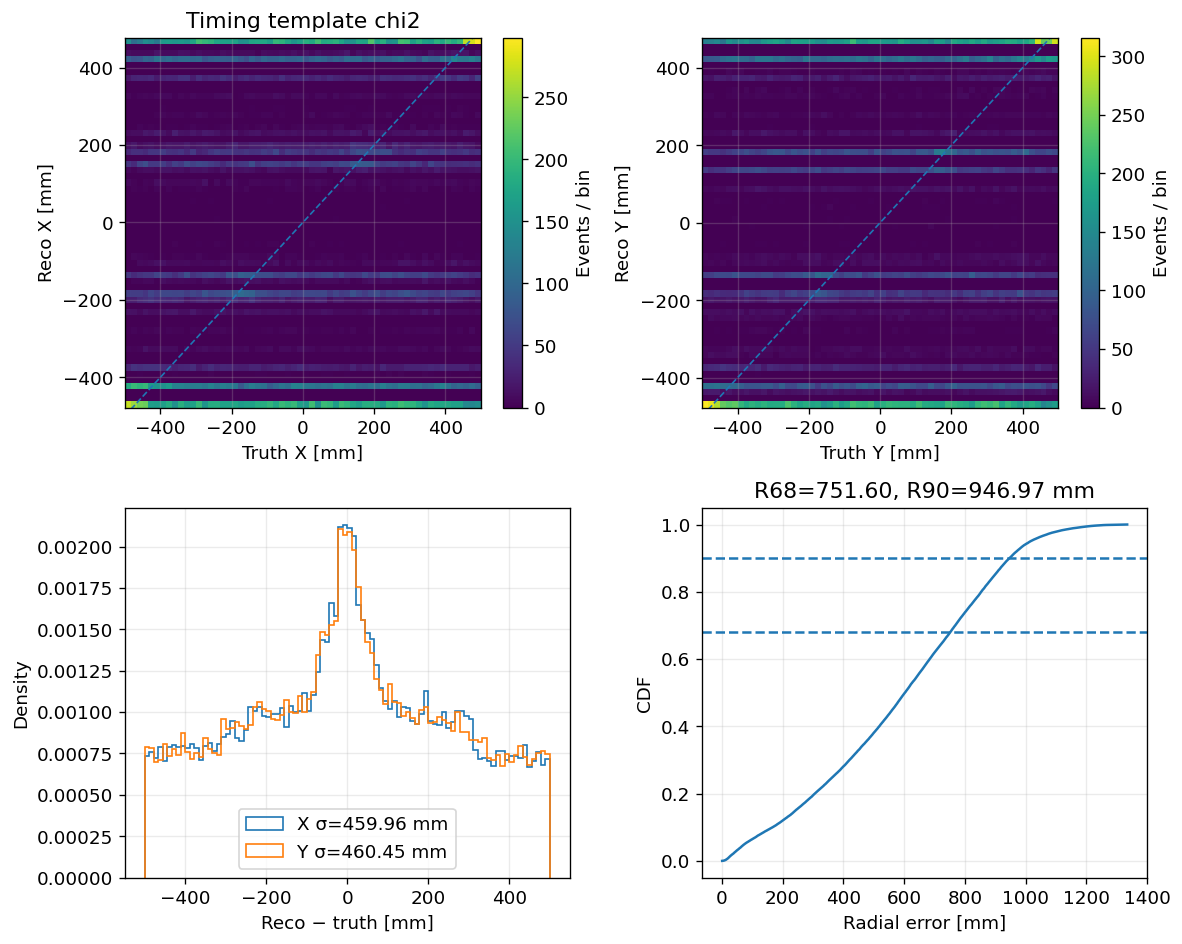

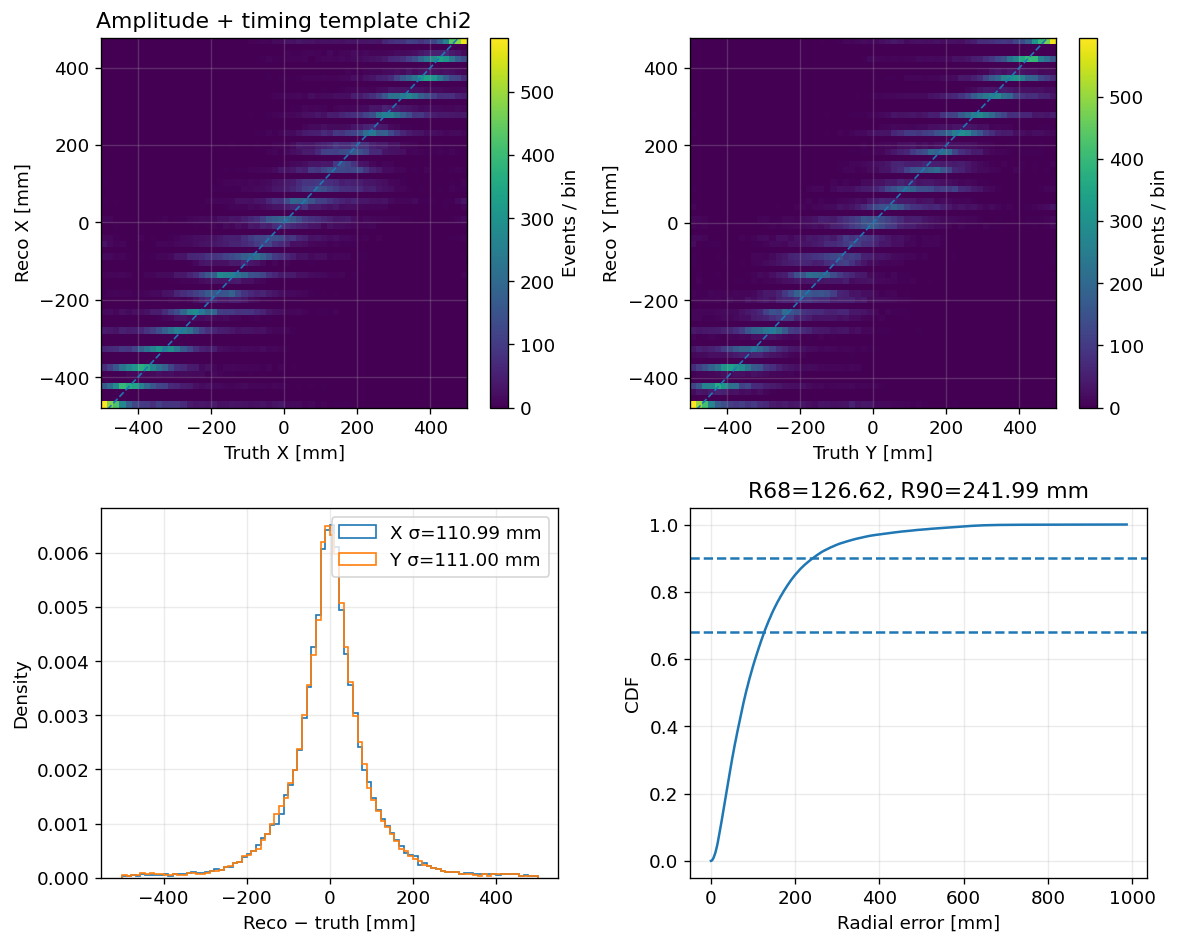

In [164]:
# 13. Detailed residual/linearity plot for every method
def performance(name,xy):
    xt=test.source_x_mm.to_numpy(float)
    yt=test.source_y_mm.to_numpy(float)
    xr,yr=xy[:,0],xy[:,1]

    m=np.isfinite(xt)&np.isfinite(yt)&np.isfinite(xr)&np.isfinite(yr)
    xt,yt,xr,yr=xt[m],yt[m],xr[m],yr[m]

    dx=xr-xt
    dy=yr-yt
    rr=np.hypot(dx,dy)

    fig,ax=plt.subplots(2,2,figsize=(10,8))

    # regular rectangular truth-vs-reco histogram
    h=ax[0,0].hist2d(xt,xr,bins=60)
    q=[min(xt.min(),xr.min()),max(xt.max(),xr.max())]
    ax[0,0].plot(q,q,"--",lw=1)
    ax[0,0].set(
        xlabel="Truth X [mm]",
        ylabel="Reco X [mm]",
        title=name
    )
    plt.colorbar(h[3],ax=ax[0,0],label="Events / bin")

    h=ax[0,1].hist2d(yt,yr,bins=60)
    q=[min(yt.min(),yr.min()),max(yt.max(),yr.max())]
    ax[0,1].plot(q,q,"--",lw=1)
    ax[0,1].set(
        xlabel="Truth Y [mm]",
        ylabel="Reco Y [mm]"
    )
    plt.colorbar(h[3],ax=ax[0,1],label="Events / bin")

    ax[1,0].hist(
        dx,bins=90,range=(-500,500),histtype="step",density=True,
        label=f"X σ={np.std(dx):.2f} mm"
    )
    ax[1,0].hist(
        dy,bins=90,range=(-500,500),histtype="step",density=True,
        label=f"Y σ={np.std(dy):.2f} mm"
    )
    ax[1,0].set(
        xlabel="Reco − truth [mm]",
        ylabel="Density"
    )
    ax[1,0].legend()

    r=np.sort(rr)
    ax[1,1].plot(r,np.arange(1,len(r)+1)/len(r))
    ax[1,1].axhline(.68,ls="--")
    ax[1,1].axhline(.90,ls="--")
    ax[1,1].set(
        xlabel="Radial error [mm]",
        ylabel="CDF",
        title=f"R68={np.quantile(rr,.68):.2f}, R90={np.quantile(rr,.90):.2f} mm"
    )

    plt.tight_layout()
    safe=re.sub("[^A-Za-z0-9]+","_",name)
    plt.savefig(OUT/f"reco_{safe}.png",bbox_inches="tight")
    plt.show()

for name,xy in pred.items():
    performance(name,xy)

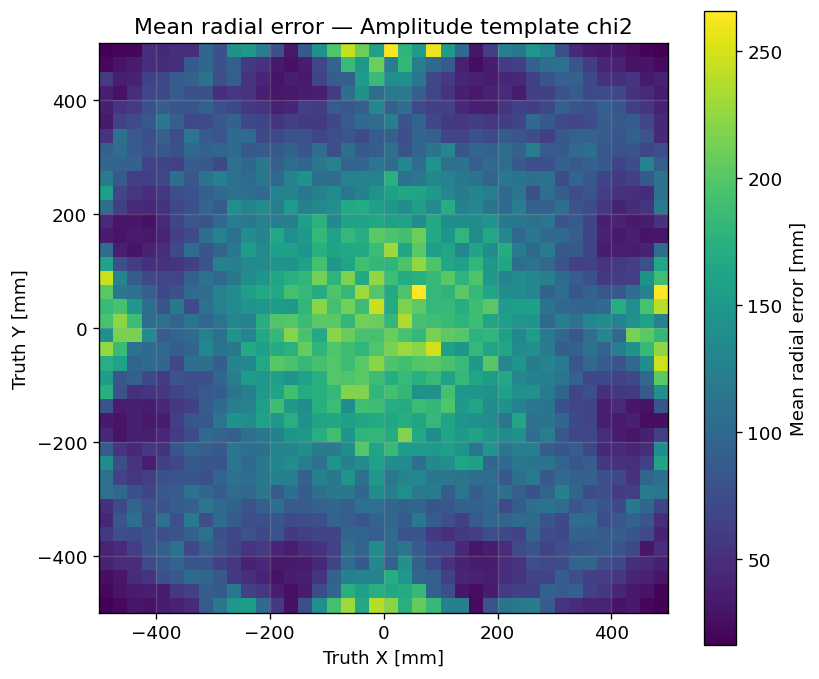

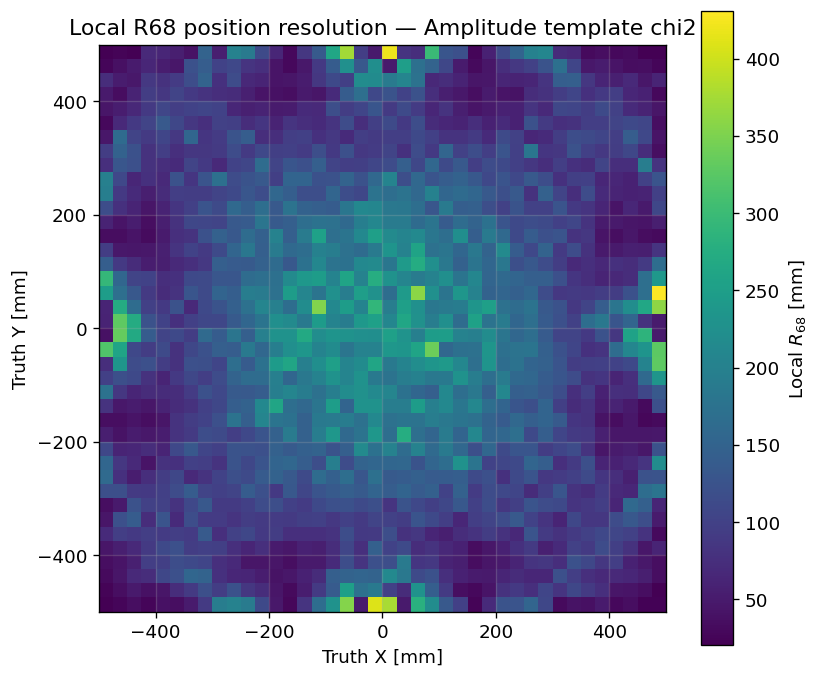

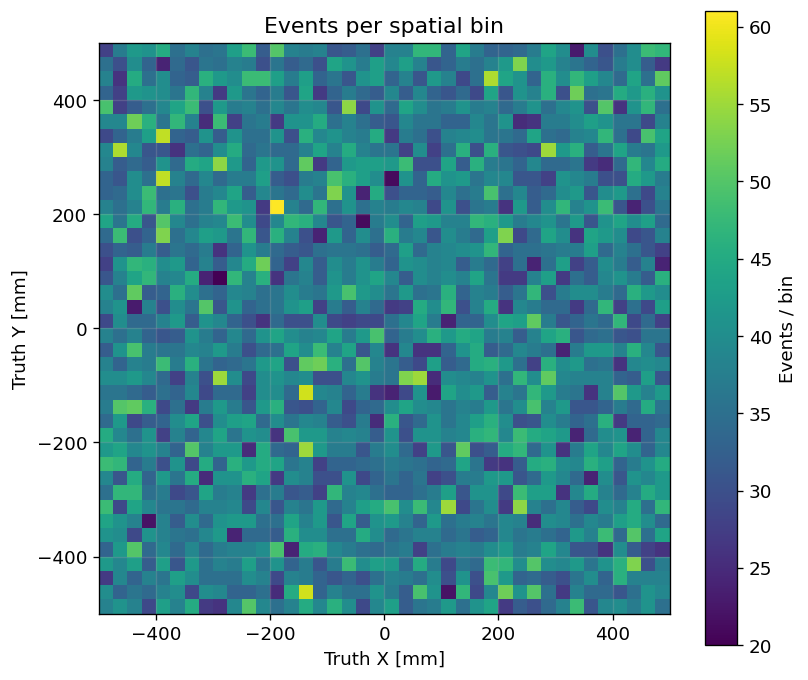

In [165]:
# 14. Spatial resolution map for the best method
xy=pred[best]

xt=test.source_x_mm.to_numpy(float)
yt=test.source_y_mm.to_numpy(float)
dx=xy[:,0]-xt
dy=xy[:,1]-yt
r=np.hypot(dx,dy)

# ------------------------------------------------------------
# A. Mean radial error map
# ------------------------------------------------------------
fig,ax=plt.subplots(figsize=(7,6))

histmap(ax,xt,yt,z=r,statistic="mean",bins=XY_BINS,min_count=5,cbar_label="Mean radial error [mm]")
ax.set(xlabel="Truth X [mm]",ylabel="Truth Y [mm]",title=f"Mean radial error — {best}")

plt.tight_layout()
plt.savefig(OUT/"07_best_mean_radial_error_map.png",bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# B. R68 map -- more robust measure of local position resolution
# ------------------------------------------------------------
def q68(v):
    return np.nanquantile(v,0.68) if len(v)>=5 else np.nan

fig,ax=plt.subplots(figsize=(7,6))

histmap(ax,xt,yt,z=r,statistic=q68,bins=XY_BINS,min_count=5,cbar_label=r"Local $R_{68}$ [mm]")
ax.set(xlabel="Truth X [mm]",ylabel="Truth Y [mm]",title=f"Local R68 position resolution — {best}")

plt.tight_layout()
plt.savefig(OUT/"08_best_R68_map.png",bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# C. Event count map
# ------------------------------------------------------------
fig,ax=plt.subplots(figsize=(7,6))

histmap(ax,xt,yt,z=None,bins=XY_BINS,min_count=1,cbar_label="Events / bin")
ax.set(xlabel="Truth X [mm]",ylabel="Truth Y [mm]",title="Events per spatial bin")

plt.tight_layout()
plt.savefig(OUT/"09_spatial_event_count.png",bbox_inches="tight")
plt.show()

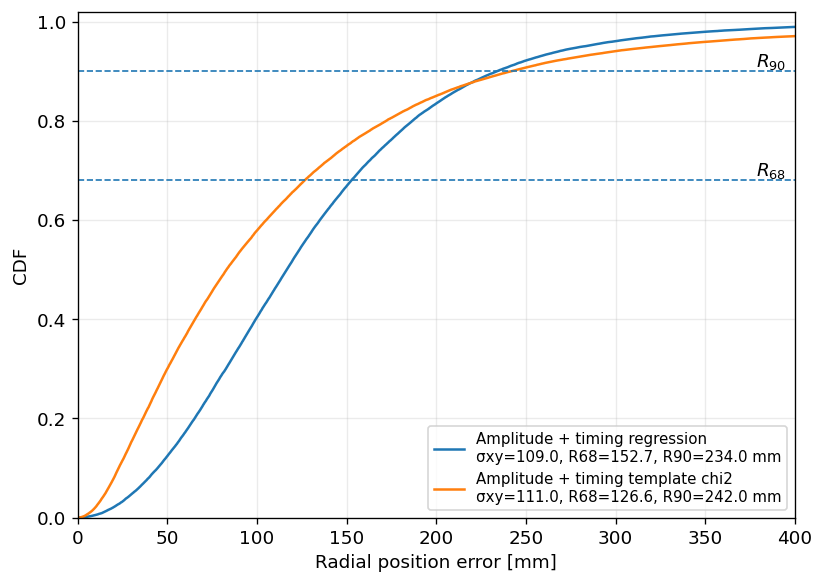

In [166]:
# plotting the radial errr CDF for the best method
fig,ax=plt.subplots(figsize=(7,5))

for name in ["Amplitude + timing regression","Amplitude + timing template chi2"]:
    xy=pred[name]
    dx=xy[:,0]-test.source_x_mm.to_numpy()
    dy=xy[:,1]-test.source_y_mm.to_numpy()
    r=np.hypot(dx,dy); r=r[np.isfinite(r)]
    rs=np.sort(r)
    sxy=np.sqrt((np.std(dx)**2+np.std(dy)**2)/2)
    R68,R90=np.quantile(r,[.68,.90])
    ax.plot(rs,np.arange(1,len(rs)+1)/len(rs),
            label=f"{name}\nσxy={sxy:.1f}, R68={R68:.1f}, R90={R90:.1f} mm")

for y,t in [(.68,r"$R_{68}$"),(.90,r"$R_{90}$")]:
    ax.axhline(y,ls="--",lw=1); ax.text(395,y+.01,t,ha="right")

ax.set(xlabel="Radial position error [mm]",ylabel="CDF",xlim=(0,400),ylim=(0,1.02))
ax.legend(fontsize=9)
plt.tight_layout(); plt.savefig(OUT/"10_radial_error_CDF.png",bbox_inches="tight"); plt.show()

# Interpretation

For this SiPM design, the most important physics comparison is

$$
\mathrm{Amplitude\ only}
\quad\rightarrow\quad
\mathrm{Timing\ only}
\quad\rightarrow\quad
\mathrm{Amplitude+Timing}.
$$

In particular, compare:

- `Amplitude regression` with `Amplitude + timing regression`;
- `Amplitude template chi2` with `Amplitude + timing template chi2`.

A useful quantitative improvement is

$$
I_{R68}
=
\frac{R_{68}^{A}-R_{68}^{A+T}}{R_{68}^{A}}\times100\%.
$$

If the combined estimator improves $R_{68}$, $\sigma_x$, and $\sigma_y$ consistently across the detector surface, that is direct evidence that timing adds independent spatial information.

The template method is especially relevant for a real prototype because the response maps can eventually be obtained using a scanned source or an external tracking telescope.

### Experimental realism

The present timing resolution is an optical-limit result unless the simulation also includes SiPM/electronics effects such as SPTR/TTS, PDE fluctuations, dark counts, crosstalk, afterpulsing, electronics noise/bandwidth and the actual timing-pickoff method.